# CMIP6 torchcrop runs — trends

Theil–Sen slopes with Mann–Kendall tests, per model, region and cell. Cell-level significance uses
Benjamini–Hochberg false-discovery control at α = 0.10, because a field of per-cell tests at p < 0.05
over-counts (Wilks 2016). Every trend here is climate and CO₂ alone, since the crop system is fixed;
a farm-scale trend also carries breeding and management.


**Reading these numbers**

* **Scope.** Torchcrop only, on calibrated parameters, for 4 models × 5 experiments, one run per
  model-experiment. Differences between experiments of one model include internal variability.
* **Cells.** The 59,304 cells every run simulated, weighted by cropland area. Each forcing has its own
  frame, and all 5,572 dropped cells lie outside the box the frames share.
* **Fixed crop system.** Cultivar, fertiliser and sowing (per-cell median of the MSWX SIMPLACE dates)
  do not change, so nothing here includes adaptation and sowing cannot respond to the forcing.
* **Wind** is an MSWX climatology in every run, so wind carries no scenario signal.
* **`hist-aer` holds CO₂ at 1850 (284 ppm)**; the other experiments follow their own CO₂. A contrast with
  `hist-aer` therefore mixes the climate effect with the CO₂ effect on the crop.
* **`yield_t_ha` excludes heat sterility.** `adjusted_yield_t_ha` = yield × (1 − heat stress). The
  calibration and evaluation use `yield_t_ha`, so it is the primary series here (see 04's sensitivity test).
* **No season 2015.** Historical runs end at harvest 2014, and SSP runs start with sowing in 2015.

## Findings

**Trends follow CO₂: strongly significant where CO₂ rises fast, absent where it does not.**

* **1951–2014, Europe:** `historical` +0.12 to +0.19 t/ha per decade, `hist-GHG` +0.09 to +0.14, both significant in every model. `hist-aer` is −0.03 to +0.01 and significant in none.
* **Cropland with a significant rise, after false-discovery control:** 77 % in `historical`, 56 % in `hist-GHG` and 2 % in `hist-aer`, with almost no significant falls.
* **30 years is short:** over 1985–2014, only 2 of 4 models have a significant Europe trend in `historical`, and the cell maps disagree on sign in the east.
* **Future:** `ssp370` 2051–2100 rises +0.08 to +0.19 t/ha per decade. `ssp126` 2051–2100 is flat to slightly falling (−0.06 to +0.01), with 0 % of cropland significant. Its yield peaks in 2039–2078 depending on model, while `ssp370` is still rising at the end of the run in every model.
* **Emergence beyond one interannual standard deviation by 2090:** 73 % of cropland in `ssp370` and 22 % in `ssp126`.
* **Recent trend:** MSWX 2000–2024 is +0.12 t/ha per decade (p = 0.27), inside the models' −0.05 to +0.19, and no run is significant over that window.
* **Method check:** median lag-1 autocorrelation of detrended seasons is −0.04 to +0.03, so Mann–Kendall's independence assumption holds. Forcing trends roughly add up, with residuals of +0.00 to +0.10 t/ha per decade, largest in ACCESS-ESM1-5.

## 0. Setup

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import scenarios as sc
from cropmodelling4eu.evaluation.plots import save
from cropmodelling4eu.evaluation.style import SEQUENTIAL_CMAP, DIVERGING_CMAP, use_style

logging.basicConfig(level=logging.WARNING, force=True)
PALETTE = use_style("light")
plt.rcParams["figure.dpi"] = 90
FIGURES, TABLES = sc.table_dir("trends")
cells = sc.load_cells()
y = sc.cube("yield_t_ha")
EXP_COLOURS = {"historical": PALETTE["primary"], "hist-GHG": PALETTE["series_4"], "hist-aer": PALETTE["series_3"],
               "ssp126": PALETTE["series_1"], "ssp370": PALETTE["series_2"]}
MODEL_COLOURS = dict(zip(sc.MODELS, (PALETTE[f"series_{i}"] for i in (1, 2, 3, 5))))
SPAN = lambda s: f"{s[0]}–{s[1]}"

WINDOWS = {"1951–2014": ((1951, 2014), sc.HISTORICAL), "1985–2014": ((1985, 2014), sc.HISTORICAL),
           "2016–2050": ((2016, 2050), sc.FUTURE), "2051–2100": ((2051, 2100), sc.FUTURE)}


def cell_trends(data):
    slopes, pvalues = {}, {}
    for name, (span, experiments) in WINDOWS.items():
        for e in experiments:
            block = sc.period(data.sel(experiment=e), span)
            years = block.year.values
            per_model = [sc.sen_mk(block.sel(model=m).values, years) for m in sc.MODELS]
            slopes[name, e] = xr.DataArray(np.stack([p[0] for p in per_model]), dims=("model", "cell"), coords={"model": list(sc.MODELS), "cell": data.cell})
            pvalues[name, e] = np.stack([p[1] for p in per_model])
    return slopes, pvalues

print(f"{cells.n} cells; outputs in {FIGURES.parent}")

59304 cells; outputs in /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/cmip6/analysis/trends


## 1. Does a trend test apply?

Mann–Kendall assumes independent seasons. Lag-1 autocorrelation of the detrended seasons, per cell, shows whether that holds. Each season's crop starts from a re-initialised soil and has independent weather, so it should be near zero.

In [2]:
block = sc.period(y.sel(experiment="historical"), (1951, 2014))
fit = block.polyfit("year", deg=1)["polyfit_coefficients"]
resid = block - xr.polyval(block["year"], fit)
lag1 = xr.corr(resid.isel(year=slice(1, None)).assign_coords(year=np.arange(63)), resid.isel(year=slice(None, -1)).assign_coords(year=np.arange(63)), dim="year")
print(lag1.quantile([0.05, 0.5, 0.95], dim="cell").to_pandas().round(3))

model     ACCESS-ESM1-5  IPSL-CM6A-LR  MIROC6  MRI-ESM2-0
quantile                                                 
0.05             -0.184        -0.220  -0.196      -0.204
0.50              0.025        -0.037   0.014       0.016
0.95              0.294         0.143   0.220       0.223


## 2. Regional trends

Theil–Sen per decade per model, on the region's mean series, with the Mann–Kendall result (`*` p < 0.05).

In [3]:
series = sc.regional_mean(y)
base = sc.clim(series.sel(experiment="historical"), sc.BASELINE)
rows = []
for name, (span, experiments) in WINDOWS.items():
    for e in experiments:
        for m in sc.MODELS:
            for r in series.region.values:
                s = sc.period(series.sel(model=m, experiment=e, region=r), span)
                slope, p = sc.sen_mk(s.values[:, None], s.year.values)
                rows.append({"window": name, "experiment": e, "model": m, "region": r, "slope": float(slope[0]), "p": float(p[0]),
                             "slope_pct": 100.0 * float(slope[0]) / float(base.sel(model=m, region=r))})
regional = pd.DataFrame(rows)
regional.to_csv(TABLES / "regional_trends.csv", index=False)
europe = regional[regional["region"] == "Europe"].assign(cell=lambda f: f["slope"].map("{:+.3f}".format) + np.where(f["p"] < 0.05, "*", ""))
print("Europe, t/ha per decade:")
display(europe.pivot(index=["window", "experiment"], columns="model", values="cell"))

Europe, t/ha per decade:


model                ACCESS-ESM1-5 IPSL-CM6A-LR   MIROC6 MRI-ESM2-0
window    experiment                                               
1951–2014 hist-GHG         +0.094*      +0.109*  +0.144*    +0.138*
          hist-aer          -0.029       +0.003   +0.013     -0.000
          historical       +0.168*      +0.116*  +0.187*    +0.184*
1985–2014 hist-GHG          +0.105       +0.081   +0.173     +0.003
          hist-aer          -0.020       -0.066   +0.031     +0.097
          historical        +0.041       +0.024  +0.197*    +0.173*
2016–2050 ssp126            +0.091       +0.080  +0.139*    +0.129*
          ssp370           +0.205*       +0.161   +0.122    +0.173*
2051–2100 ssp126            -0.060       +0.008   -0.021     -0.048
          ssp370           +0.127*      +0.083*  +0.185*    +0.181*

Trend per decade as % of each model's baseline, per region. Each dot is a model, and the bar is their mean:

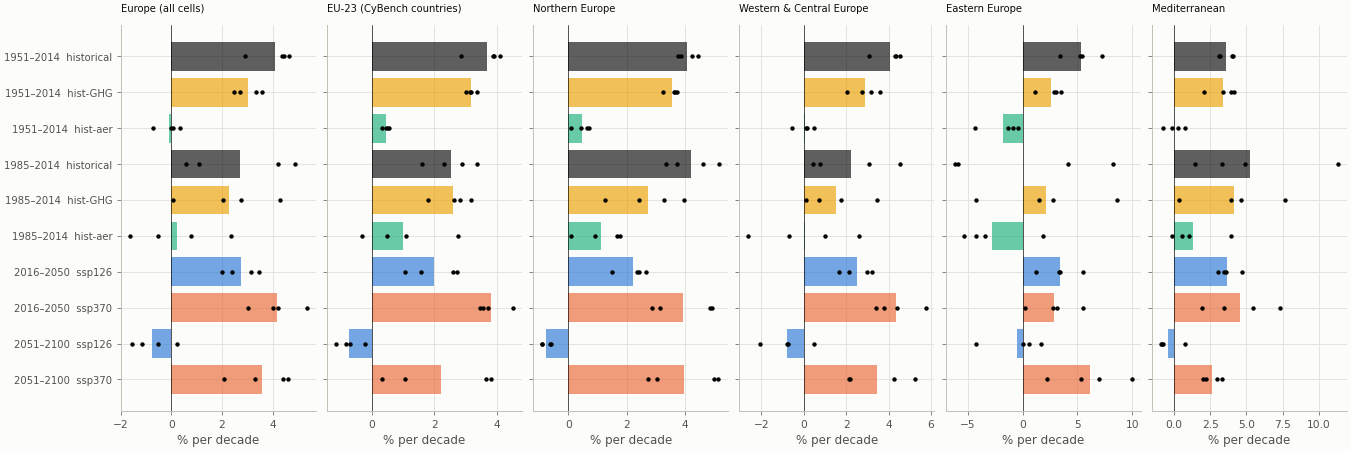

In [4]:
order = [(w, e) for w, (_, es) in WINDOWS.items() for e in es]
regions = list(sc.REGION_NAMES)
fig, axes = plt.subplots(1, len(regions), figsize=(15.0, 5.0), sharey=True, layout="constrained")
for ax, r in zip(axes, regions):
    block = regional[regional["region"] == r]
    for i, (w, e) in enumerate(order):
        vals = block[(block["window"] == w) & (block["experiment"] == e)]["slope_pct"]
        ax.barh(i, vals.mean(), color=EXP_COLOURS[e], alpha=0.65)
        ax.plot(vals, [i] * len(vals), "o", ms=2.5, color="k")
    ax.axvline(0, color="k", lw=0.5)
    ax.set_title(sc.REGION_NAMES[r], fontsize=8)
    ax.set_xlabel("% per decade")
axes[0].set_yticks(range(len(order)), [f"{w}  {e}" for w, e in order], fontsize=8)
axes[0].invert_yaxis()
save(fig, "regional_trends", FIGURES)
plt.show()

## 3. Trend maps

The multi-model mean of per-cell slopes. Hatching marks cells where fewer than 3 models share the sign.

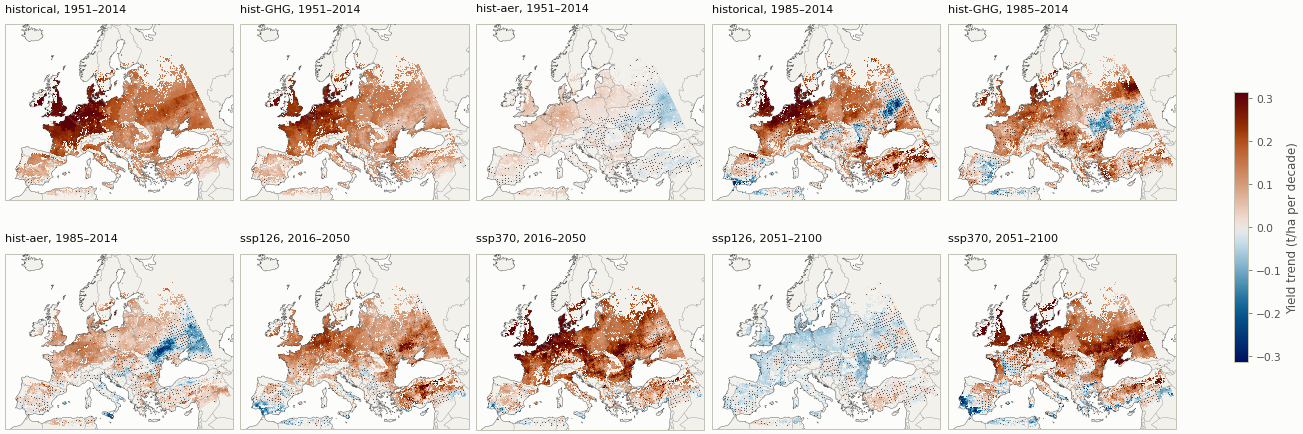

In [5]:
slopes, pvalues = cell_trends(y)
keys = list(slopes)
limit = float(np.nanquantile(np.abs(np.stack([slopes[k].mean("model").values for k in keys])), 0.98))
fig, axes = sc.map_axes(2, 5, 2.9, 2.3)
for ax, key in zip(axes.ravel(), keys):
    mesh = sc.draw_map(ax, slopes[key].mean("model").values, title=f"{key[1]}, {key[0]}", hatch=~sc.agreement(slopes[key]).values, cmap=DIVERGING_CMAP, vmin=-limit, vmax=limit)
fig.colorbar(mesh, ax=axes, shrink=0.6, label="Yield trend (t/ha per decade)")
save(fig, "trend_maps", FIGURES)
plt.show()

## 4. How much cropland trends significantly?

Cropland share with a significant rise or fall after false-discovery control, per run, then averaged over models. The ranges give the lowest and highest model.

In [6]:
w = cells.weight / cells.weight.sum()
rows = []
for key in keys:
    up, down = [], []
    for k, m in enumerate(sc.MODELS):
        mask = sc.fdr(pvalues[key][k])
        slope = slopes[key].sel(model=m).values
        up.append(100 * w[mask & (slope > 0)].sum())
        down.append(100 * w[mask & (slope < 0)].sum())
    rows.append({"window": key[0], "experiment": key[1], "rising (%)": f"{np.mean(up):.0f} [{min(up):.0f}, {max(up):.0f}]", "falling (%)": f"{np.mean(down):.0f} [{min(down):.0f}, {max(down):.0f}]"})
significant = pd.DataFrame(rows)
significant.to_csv(TABLES / "significant_area.csv", index=False)
display(significant)

,window,experiment,rising (%),falling (%)
0,1951–2014,historical,"77 [62, 88]","0 [0, 0]"
1,1951–2014,hist-GHG,"56 [44, 68]","0 [0, 0]"
2,1951–2014,hist-aer,"2 [0, 4]","2 [0, 7]"
3,1985–2014,historical,"19 [6, 33]","0 [0, 0]"
4,1985–2014,hist-GHG,"2 [0, 8]","0 [0, 0]"
5,1985–2014,hist-aer,"0 [0, 0]","0 [0, 0]"
6,2016–2050,ssp126,"2 [0, 8]","0 [0, 0]"
7,2016–2050,ssp370,"25 [8, 40]","0 [0, 1]"
8,2051–2100,ssp126,"0 [0, 0]","0 [0, 0]"
9,2051–2100,ssp370,"43 [24, 58]","3 [2, 6]"


## 5. Do the forcing trends add up?

1951–2014 in Europe. If forcings were additive, the `historical` trend would equal `hist-GHG` + `hist-aer`. The `hist-aer` trend has no CO₂ rise behind it, so it is the only climate-only trend in the table.

In [7]:
pivot = regional[(regional["window"] == "1951–2014")].pivot_table(index=["region", "model"], columns="experiment", values="slope")[list(sc.HISTORICAL)]
pivot["hist-GHG + hist-aer"] = pivot["hist-GHG"] + pivot["hist-aer"]
pivot["residual"] = pivot["historical"] - pivot["hist-GHG + hist-aer"]
pivot.to_csv(TABLES / "forcing_trend_sum.csv")
display(pivot.loc["Europe"].round(3))

experiment,historical,hist-GHG,hist-aer,hist-GHG + hist-aer,residual
model,,,,,
ACCESS-ESM1-5,0.168,0.094,-0.029,0.065,0.103
IPSL-CM6A-LR,0.116,0.109,0.003,0.112,0.004
MIROC6,0.187,0.144,0.013,0.157,0.030
MRI-ESM2-0,0.184,0.138,-0.000,0.137,0.047


## 6. When does a yield peak?

The year of each model's highest 21-year mean, per region and experiment. A year at the end of the run means yield is still rising in 2100, not that it peaks there.

In [8]:
smooth = series.rolling(year=21, center=True, min_periods=21).mean()
peak = pd.DataFrame({(e, r): {m: int(smooth.sel(experiment=e, region=r, model=m).dropna("year").idxmax()) for m in sc.MODELS}
                     for e in sc.FUTURE for r in series.region.values}).T
peak.index.names = ["experiment", "region"]
peak.to_csv(TABLES / "peak_year.csv")
display(peak)

ACCESS-ESM1-5  IPSL-CM6A-LR  MIROC6  MRI-ESM2-0
experiment region                                                 
ssp126     Europe           2039          2078    2064        2055
           EU23             2041          2061    2064        2055
           NEU              2066          2051    2066        2056
           WCE              2039          2090    2064        2055
           EEU              2039          2078    2077        2065
           MED              2033          2060    2041        2053
ssp370     Europe           2090          2090    2090        2090
           EU23             2082          2078    2089        2090
           NEU              2082          2087    2090        2090
           WCE              2090          2078    2090        2090
           EEU              2090          2090    2090        2088
           MED              2090          2080    2088        2090

## 7. Time of emergence

The first year after which a cell's 21-year mean stays more than one interannual standard deviation (of 1985–2014) from its baseline, until the run ends. Year per model, then the multi-model median; cells that never emerge are blank. The threshold is a convention, so read this as a ranking of where the signal shows first, not as a date.

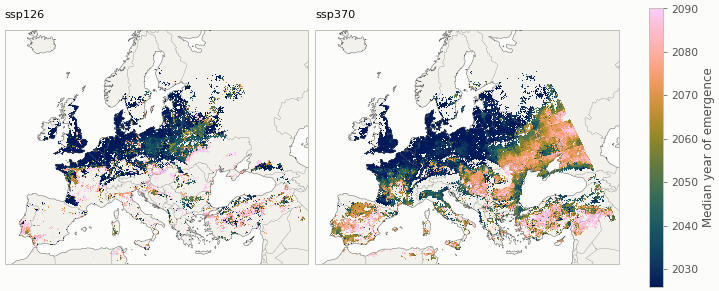

Cropland emerged by year (%), multi-model median of models' share:


,ssp126,ssp370
2040,14.0,29.0
2060,17.0,41.0
2080,19.0,61.0
2090,22.0,73.0


In [9]:
def emergence(data, experiment, k=1.0):
    base = sc.period(data.sel(experiment="historical"), sc.BASELINE)
    mean, sd = base.mean("year").values, base.std("year").values
    run = sc.period(data.sel(experiment=experiment), (2016, 2100))
    rolled = run.rolling(year=21, center=True, min_periods=21).mean().dropna("year", how="all")
    years = rolled.year.values
    departed = np.abs(rolled.transpose("year", "model", "cell").values - mean) > k * sd
    # The last year not departed, plus one, is when the departure becomes permanent.
    last_inside = departed.shape[0] - 1 - np.argmax(~departed[::-1], axis=0)
    first = np.where(departed.all(0), 0, last_inside + 1)
    out = np.where(first < len(years), years[np.minimum(first, len(years) - 1)], np.nan)
    return xr.DataArray(out, dims=("model", "cell"), coords={"model": list(sc.MODELS), "cell": data.cell})

toe = {e: emergence(y, e) for e in sc.FUTURE}
fig, axes = sc.map_axes(1, 2, 4.0, 4.0)
for ax, (e, field) in zip(axes[0], toe.items()):
    mesh = sc.draw_map(ax, field.median("model").values, cmap=SEQUENTIAL_CMAP, vmin=2026, vmax=2090, title=e)
fig.colorbar(mesh, ax=axes, shrink=0.7, label="Median year of emergence")
save(fig, "time_of_emergence", FIGURES)
plt.show()
w = cells.weight / cells.weight.sum()
print("Cropland emerged by year (%), multi-model median of models' share:")
display(pd.DataFrame({e: {year: float(np.median([100 * w[(f.sel(model=m).values <= year)].sum() for m in sc.MODELS])) for year in (2040, 2060, 2080, 2090)} for e, f in toe.items()}).round(0))

## 8. Trends in the crop processes

Europe, multi-model mean Theil–Sen per decade with the model range. Compared with the yield trend, this shows which process moves with it.

In [10]:
PROCESS = ["yield_t_ha", "biomass_g_m2", "max_lai", "days_to_anthesis", "days_to_maturity", "tranrf_mean", "nni_mean", "heat_stress_factor"]
rows = []
for v in PROCESS:
    reg = sc.regional_mean(sc.cube(v), regions=("Europe",)).sel(region="Europe")
    for name, (span, experiments) in WINDOWS.items():
        for e in experiments:
            s = sc.period(reg.sel(experiment=e), span)
            vals = [float(sc.sen_mk(s.sel(model=m).values[:, None], s.year.values)[0][0]) for m in sc.MODELS]
            rows.append({"variable": v, "window": name, "experiment": e, "cell": f"{np.mean(vals):+.3g} [{min(vals):+.3g}, {max(vals):+.3g}]"})
process = pd.DataFrame(rows).pivot(index=["window", "experiment"], columns="variable", values="cell")[PROCESS]
process.to_csv(TABLES / "process_trends.csv")
display(process)

variable                               yield_t_ha           biomass_g_m2  \
window    experiment                                                       
1951–2014 hist-GHG       +0.121 [+0.0941, +0.144]   +30.8 [+28.4, +33.3]   
          hist-aer    -0.00319 [-0.0287, +0.0131]  +0.802 [-4.25, +3.53]   
          historical      +0.164 [+0.116, +0.187]     +37.1 [+32, +39.7]   
1985–2014 hist-GHG     +0.0905 [+0.00288, +0.173]   +24.6 [+15.8, +29.9]   
          hist-aer     +0.0102 [-0.0662, +0.0968]   +12.3 [+5.55, +25.4]   
          historical     +0.109 [+0.0237, +0.197]     +36.8 [+22.7, +51]   
2016–2050 ssp126          +0.11 [+0.0804, +0.139]   +26.7 [+24.4, +32.2]   
          ssp370          +0.165 [+0.122, +0.205]   +38.6 [+30.2, +49.1]   
2051–2100 ssp126      -0.0301 [-0.0596, +0.00796]   -5.43 [-7.38, -2.38]   
          ssp370         +0.144 [+0.0828, +0.185]     +34.1 [+21, +42.2]   

variable                                   max_lai          days_to_anthesis  \
window    experiment                                                           
1951–2014 hist-GHG        +0.111 [+0.0886, +0.131]     -0.985 [-1.07, -0.81]   
          hist-aer      +0.013 [+0.00718, +0.0204]   +0.152 [-0.268, +0.417]   
          historical       +0.125 [+0.121, +0.135]     -1.05 [-1.36, -0.909]   
1985–2014 hist-GHG        +0.0782 [+0.0295, +0.13]     -1.27 [-1.82, -0.806]   
          hist-aer       +0.0892 [+0.0377, +0.116]      -1.61 [-2.02, -1.22]   
          historical      +0.129 [+0.0935, +0.162]      -3.41 [-4.45, -2.93]   
2016–2050 ssp126          +0.0847 [+0.0645, +0.12]     -1.14 [-1.9, -0.0985]   
          ssp370           +0.082 [+0.042, +0.112]     -1.39 [-3.44, +0.942]   
2051–2100 ssp126      -0.00958 [-0.0337, +0.00605]  +0.0194 [-0.834, +0.748]   
          ssp370        +0.0275 [-0.0233, +0.0802]      -2.03 [-3.24, -1.03]   

variable                       days_to_maturity  \
window    experiment                              
1951–2014 hist-GHG         -1.23 [-1.35, -1.16]   
          hist-aer    -0.00499 [-0.606, +0.261]   
          historical        -1.4 [-1.67, -1.15]   
1985–2014 hist-GHG         -1.43 [-1.77, -1.08]   
          hist-aer         -2.56 [-3.11, -1.72]   
          historical       -4.47 [-5.11, -3.92]   
2016–2050 ssp126         -1.28 [-2.14, -0.0218]   
          ssp370          -1.85 [-3.59, +0.387]   
2051–2100 ssp126        +0.048 [-0.967, +0.793]   
          ssp370            -2.47 [-3.95, -1.5]   

variable                                  tranrf_mean  \
window    experiment                                    
1951–2014 hist-GHG     +0.00029 [-0.000472, +0.00084]   
          hist-aer      -0.000161 [-0.0025, +0.00136]   
          historical  +0.000506 [-0.000609, +0.00177]   
1985–2014 hist-GHG     +0.00124 [+5.68e-07, +0.00322]   
          hist-aer     -0.000405 [-0.00619, +0.00696]   
          historical    -0.00278 [-0.00662, +0.00471]   
2016–2050 ssp126       +0.00126 [-0.000376, +0.00367]   
          ssp370       +0.000181 [-0.00127, +0.00251]   
2051–2100 ssp126       -0.000532 [-0.00274, +0.00218]   
          ssp370        -1.7e-05 [-0.00119, +0.00126]   

variable                                      nni_mean  \
window    experiment                                     
1951–2014 hist-GHG    -0.000418 [-0.000491, -0.000356]   
          hist-aer     +1.93e-05 [-7.88e-06, +4.5e-05]   
          historical  -0.000327 [-0.000412, -0.000257]   
1985–2014 hist-GHG     -0.000516 [-0.00076, -0.000149]   
          hist-aer    -2.82e-05 [-7.49e-05, +2.48e-05]   
          historical   -0.000656 [-0.00113, -0.000255]   
2016–2050 ssp126       -0.000942 [-0.00131, -0.000743]   
          ssp370         -0.00145 [-0.00182, -0.00108]   
2051–2100 ssp126      +0.000108 [-6.63e-05, +0.000274]   
          ssp370          -0.00366 [-0.0041, -0.00298]   

variable                            heat_stress_factor  
window    experiment                                    
1951–2014 hist-GH

## 9. Recent trend against the MSWX run

2000–2024 in Europe: `historical` spliced to each SSP, against the MSWX torchcrop run. 25 seasons is short, and a free-running model's trend differs by internal variability alone, so the MSWX value only needs to fall inside a plausible range.

In [11]:
mswx = sc.regional_mean(sc.mswx_cube()).sel(region="Europe")
slope, p = sc.sen_mk(mswx.values[:, None].astype(np.float32), mswx.year.values)
rows = [{"run": "MSWX", "slope": float(slope[0]), "p": float(p[0])}]
reg = series.sel(region="Europe")
for m in sc.MODELS:
    for e in sc.FUTURE:
        a, b = reg.sel(model=m, experiment="historical").sel(year=slice(2000, 2014)), reg.sel(model=m, experiment=e).sel(year=slice(2016, 2024))
        years = np.r_[a.year.values, b.year.values]
        s, q = sc.sen_mk(np.r_[a.values, b.values][:, None].astype(np.float32), years)
        rows.append({"run": f"{m} + {e}", "slope": float(s[0]), "p": float(q[0])})
recent = pd.DataFrame(rows)
recent.to_csv(TABLES / "recent_trend.csv", index=False)
display(recent.round(3))

,run,slope,p
0,MSWX,0.123,0.272
1,ACCESS-ESM1-5 + ssp126,0.076,0.359
2,ACCESS-ESM1-5 + ssp370,-0.047,0.710
3,IPSL-CM6A-LR + ssp126,0.040,0.637
4,IPSL-CM6A-LR + ssp370,0.022,0.862
5,MIROC6 + ssp126,-0.049,0.568
6,MIROC6 + ssp370,0.177,0.130
7,MRI-ESM2-0 + ssp126,0.128,0.385
8,MRI-ESM2-0 + ssp370,0.190,0.130
